In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
from xgboost import XGBRegressor
from scipy.stats import pearsonr, linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display



## Data Preparation, Cleaning & Transformation

In [3]:
path_dir = r"C:\Users\paolo\OneDrive\Desktop\Data Science Projects\predictive-model-retail-sales-forecast\data\raw"

stores = pd.read_csv(path_dir + r"\stores.csv")
sales = pd.read_csv(path_dir + r"\sales.csv")
features = pd.read_csv(path_dir + r"\features.csv")

### Inspecting dataset structure, granularity, primary keys
Notes: 
1. Each dataset connects to each other on store_id(primary key)
   
2. The `sales` table is the primary dataset, with each observation representing a unique Store × Department × Week combination

Next step is to merge datasets on `sales` which will make it easier to conduct the analsysis & build out the models; further reviewing & handling of any duplicates, missing values and/or outliers found before initial EDA

In [4]:
# Structure Insepction + Key + Granularity

# Sales grain granularity -> unique store id by department per weekly date
sales.info() # sales - 156K rows | 5 columns | PK: store_id
display(sales.head(5))
print("\n")

# Features granularity -> unique store id by weekly date
features.info() # features - 7.8k rows | 14 columns | PK: store_id
display(features.head(5))
print("\n")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday    156000 non-null  int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 6.0+ MB


,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1
3,1,4,2022-01-01,88445.24,1
4,1,5,2022-01-01,65159.85,1




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store_id      7800 non-null   int64  
 1   date          7800 non-null   object 
 2   temperature   7800 non-null   float64
 3   fuel_price    7800 non-null   float64
 4   markdown_1    7800 non-null   float64
 5   markdown_2    7800 non-null   float64
 6   markdown_3    7800 non-null   float64
 7   markdown_4    7800 non-null   float64
 8   markdown_5    7800 non-null   float64
 9   cpi           7800 non-null   float64
 10  unemployment  7800 non-null   float64
 11  is_holiday    7800 non-null   int64  
 12  holiday_name  900 non-null    object 
 13  season        7800 non-null   object 
dtypes: float64(9), int64(2), object(3)
memory usage: 853.3+ KB


,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter
3,1,2022-01-22,25.92,3.58,579.35,2589.31,2493.19,1158.14,286.01,217.32,5.28,0,NaN,Winter
4,1,2022-01-29,78.37,4.41,4436.06,1416.64,478.38,2496.36,3423.53,247.35,8.40,0,NaN,Winter


In [5]:
# Stores granularity -> store ids
stores.info() # stores - 50 rows | 4 columns | PK: store_id
display(stores.head(5)) #


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   store_id    50 non-null     int64 
 1   store_type  50 non-null     object
 2   store_size  50 non-null     int64 
 3   region      50 non-null     object
dtypes: int64(2), object(2)
memory usage: 1.7+ KB


,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South
3,4,B,88289,North
4,5,A,218696,North


### Merging datasets and Handling Dataypes, Duplicates, Missing Values
Notes:
1. **Duplicates?** - No values found; removed duplicate variables (`is_holiday_x`, `is_holiday_y`)
   
2. **Missing Values?** - `holiday_name` contains missing values for non-holiday periods. These were retained as nulls since is_holiday already indicates whether a given week is a holiday (1) or non-holiday (0). No imputation was necessary.

In [6]:
retail_sales = sales.merge(
    stores,
    on="store_id",
    how="left"
).merge(
    features,
    on=["store_id", "date"],
    how="left"
)

retail_sales = pd.DataFrame(retail_sales)
retail_sales.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday_x  156000 non-null  int64  
 5   store_type    156000 non-null  object 
 6   store_size    156000 non-null  int64  
 7   region        156000 non-null  object 
 8   temperature   156000 non-null  float64
 9   fuel_price    156000 non-null  float64
 10  markdown_1    156000 non-null  float64
 11  markdown_2    156000 non-null  float64
 12  markdown_3    156000 non-null  float64
 13  markdown_4    156000 non-null  float64
 14  markdown_5    156000 non-null  float64
 15  cpi           156000 non-null  float64
 16  unemployment  156000 non-null  float64
 17  is_holiday_y  156000 non-null  int64  
 18  holi

In [7]:
#drop duplicate columns
retail_sales.drop(columns=['is_holiday_y'], inplace=True) 

# rename holiday column
retail_sales.rename(columns={'is_holiday_x': 'is_holiday'}, inplace=True)

#convert `date` into to date format
retail_sales['date'] = pd.to_datetime(retail_sales['date'])

In [8]:
# Checking for Duplicates Values: 0 found
retail_sales.duplicated(
    subset=['store_id', 'department', 'date']
).sum()



np.int64(0)

In [9]:
# Checking for Missing Values: missing holiday names for 138K rows
pd.DataFrame({
    'missing_values': retail_sales.isnull().sum(),
    'missing_prop': (retail_sales.isnull().mean() * 100).round(2)
})

,missing_values,missing_prop
store_id,0,0.00
department,0,0.00
date,0,0.00
weekly_sales,0,0.00
is_holiday,0,0.00
store_type,0,0.00
store_size,0,0.00
region,0,0.00
temperature,0,0.00
fuel_price,0,0.00


### Adding Relevant Time-Series Columns

In [10]:
# extract date features
retail_sales['year'] = retail_sales['date'].dt.year
retail_sales['month'] = retail_sales['date'].dt.month
retail_sales['quarter'] = retail_sales['date'].dt.quarter
retail_sales['week_of_year'] = retail_sales['date'].dt.isocalendar().week.astype(int)
retail_sales['day_name'] = retail_sales['date'].dt.day_name()

# check results
display(
    retail_sales[
        ['date', 'year', 'month', 'week_of_year', 'day_name']
    ].drop_duplicates().head(20)
)

,date,year,month,week_of_year,day_name
0,2022-01-01,2022,1,52,Saturday
20,2022-01-08,2022,1,1,Saturday
40,2022-01-15,2022,1,2,Saturday
60,2022-01-22,2022,1,3,Saturday
80,2022-01-29,2022,1,4,Saturday
100,2022-02-05,2022,2,5,Saturday
120,2022-02-12,2022,2,6,Saturday
140,2022-02-19,2022,2,7,Saturday
160,2022-02-26,2022,2,8,Saturday
180,2022-03-05,2022,3,9,Saturday


## Exploratory Data Analysis (EDA)

### Goal: Understand the behaviour of target variable (`weekly_sales`) and the different drivers that may explain its variation and thus provide strong predictive signals for the model

### Understanding the Data Distribution
Rationale: Understand how weekly sales are distributed across different periods (year, month) to identify which values are typical and assess the variability that will warrant further investigation

Questions to Answer: 
1. How does avg. weekly sales vary across years & months? Are there extreme values/outliers
   
2. How much variability exists in between different time periods?

### How does avg. weekly sales vary across years & months? Are there extreme values/outliers

Data Findings:
- *Sales shape and skewness: mean > median consistent across all year and months -- right-skewed; indicating outliers with extremely high-sales observations for 1 or more weeks per month period*
  
- *Record count: count of records decreases annually, indicating fewer recorded observations in later years, potentially due to incomplete data coverage or missing records*

In [11]:
#variance and central tendencies for weekly_sales
display(retail_sales['weekly_sales'].describe().round(2))  # overall
display(retail_sales.groupby('year')['weekly_sales'].describe().round(2))  # year
display(retail_sales.groupby('month')['weekly_sales'].describe().round(2))  # month

print("Shape and skewness: mean > median consistent across all year and months -- right-skewed; indicating outliers with extremely high-sales observations for 1 or more weeks per month period")
print("Record count: count of records decreases annually, indicating fewer recorded observations in later years, potentially due to incomplete data coverage or missing records.")


count    156000.00
mean      56503.49
std       46717.49
min         819.66
25%       21255.96
50%       43394.87
75%       79604.11
max      505958.73
Name: weekly_sales, dtype: float64

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2022,53000.0,56431.33,46426.90,890.94,21308.09,43386.48,79363.64,489823.07
2023,52000.0,56527.24,46535.95,926.65,21242.56,43528.60,79881.43,461451.81
2024,51000.0,56554.26,47201.59,819.66,21202.27,43271.74,79588.25,505958.73


,count,mean,std,min,25%,50%,75%,max
month,,,,,,,,
1,13000.0,59409.68,46973.30,1194.24,22978.38,46362.53,83630.64,306431.19
2,12000.0,56327.29,43966.09,966.33,21607.85,43844.36,80356.36,241411.13
3,13000.0,49096.70,37924.13,890.94,18961.95,38664.15,70658.16,203034.55
4,14000.0,49509.00,38195.93,973.73,19366.45,39421.57,70606.36,205628.37
5,12000.0,48642.59,37851.08,926.65,18866.80,38001.89,69324.37,204121.34
6,13000.0,49130.17,37976.63,860.58,19118.74,39086.88,70062.59,201440.99
7,14000.0,51878.72,40679.18,985.49,19929.74,40336.90,74232.20,255653.35
8,13000.0,49289.19,38184.99,819.66,19077.17,38490.20,70957.68,210407.92
9,13000.0,62113.26,49399.25,954.13,23821.00,48171.52,88334.54,343671.26


Shape and skewness: mean > median consistent across all year and months -- right-skewed; indicating outliers with extremely high-sales observations for 1 or more weeks per month period
Record count: count of records decreases annually, indicating fewer recorded observations in later years, potentially due to incomplete data coverage or missing records.


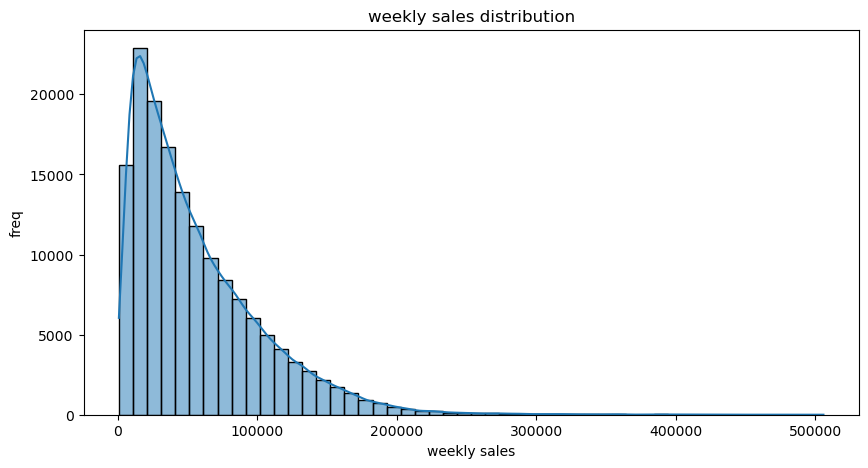

count    156000.00
mean      56503.49
std       46717.49
min         819.66
25%       21255.96
50%       43394.87
75%       79604.11
max      505958.73
Name: weekly_sales, dtype: float64

In [12]:
# weekly_sales distribution
plt.figure(figsize=(10,5))
sns.histplot(retail_sales['weekly_sales'], bins=50, kde=True)
plt.title('weekly sales distribution')
plt.xlabel('weekly sales')
plt.ylabel('freq')
plt.show()

display(retail_sales['weekly_sales'].describe().round(2))  # overall


### How much variability exists in between different time periods?
- **CV Definition:** Coefficient of Variation - measure relative variability away from the mean; to help me understand how much sales fluctuate happens for certain time periods
  
- **Formula for CV:** std / mean * 100

Data Findings:
- *Sales exhibit consistently high relative variability across months for every year, with most variability occuring on nov-dec indicating seasonality factors*

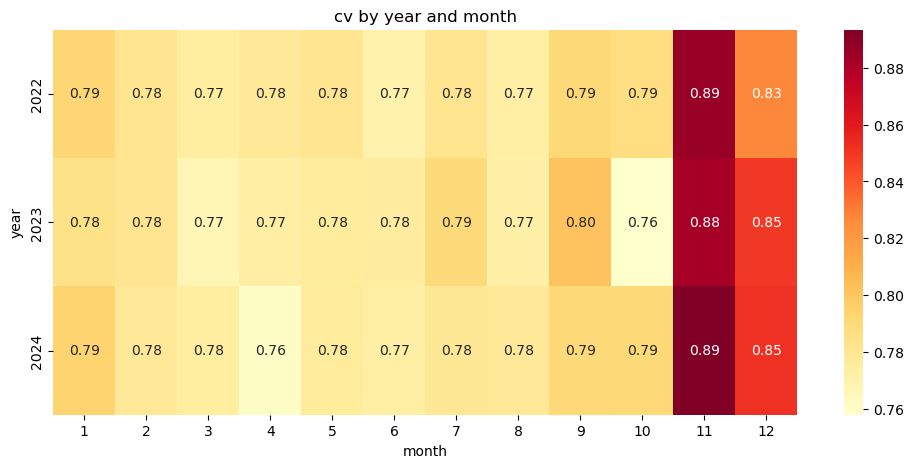

Sales variability: sales exhibit consistently high relative variability across months for every year, with most variability occuring on nov-dec indicating seasonality factors


In [13]:
year_month_cv = retail_sales.pivot_table(
    index='year',
    columns='month',
    values='weekly_sales',
    aggfunc=lambda x: x.std() / x.mean()
)

plt.figure(figsize=(12, 5))
sns.heatmap(year_month_cv, annot=True, fmt='.2f', cmap='YlOrRd')

plt.title('cv by year and month')
plt.show()

print("Sales variability: sales exhibit consistently high relative variability across months for every year, with most variability occuring on nov-dec indicating seasonality factors")

## Looking for Historical, Seasonality, Macro Sales Trends
**Rationale:** Since this is a predictive/forecasting goal, the key part of this section is mainly for looking for trends in historical sales behavior and seasonality is essential to determine whether past performance and recent sales trends can provide useful signals for future predictions

Questions to Answer:
1. Has the business been consistently growing or declining year over year?
   
2. Where do sales follow recurring seasonal patterns?
   
3. Do holidays affect weekly sales? How large is the difference? And is the difference consistent across years?
   
4. Do previous sales help explain future sales? How strong is this relationship?
   
5. Do macro-economic factors like cpi, unemployment and promotional markdowns and its changes have a correlation with the movement of weekly sales?

In [14]:
#sales time period
print("Min Date:", retail_sales['date'].min())
print("Max Date:", retail_sales['date'].max())

display(retail_sales.groupby('year')['week_of_year'].nunique())


Min Date: 2022-01-01 00:00:00
Max Date: 2024-12-21 00:00:00


year
2022    52
2023    52
2024    51
Name: week_of_year, dtype: int64

### Has the business been consistently growing or declining year over year?

Data Findings:
- *Growth Pattern: Relatively Stable; total sales have been declining slightly YoY by ~2%, but avg. weekly sales growth have remained relatively stable (0% ~ 1%)*

In [15]:
yearly_sales = retail_sales.groupby('year').agg(
    recorded_weeks=('week_of_year', 'nunique'),
    total_sales_in_millions=('weekly_sales', 'sum'),
    avg_weekly_sales=('weekly_sales', 'mean')
)

yearly_sales['total_sales_in_millions'] = yearly_sales['total_sales_in_millions'] / 1000000
yearly_sales['yoy_growth'] = yearly_sales['total_sales_in_millions'].pct_change() * 100
yearly_sales['avg_weekly_sales_growth'] = yearly_sales['avg_weekly_sales'].pct_change() * 100

display(yearly_sales.round(2))

print("Growth/Decline: total sales have been declining YoY, but avg. weekly sales growth have remained relatively stable")

,recorded_weeks,total_sales_in_millions,avg_weekly_sales,yoy_growth,avg_weekly_sales_growth
year,,,,,
2022,52,2990.86,56431.33,NaN,NaN
2023,52,2939.42,56527.24,-1.72,0.17
2024,51,2884.27,56554.26,-1.88,0.05


Growth/Decline: total sales have been declining YoY, but avg. weekly sales growth have remained relatively stable


### Do sales follow recurring seasonal patterns?

Data Findings:
- *Overally weekly sales follow the same recurring seasonal shape, with a relatively stable middle of the year and stronger sales toward year-end. implying seasonality signals like month and week_of_year capture good predictive signals (Fig. A)*
  
- *Despite similar seasonal patterns, 2024 exhibits differences in spike timing and volume, as well as BAU sales movements, **suggesting also alone that annual seasonality alone cannot fully explain sales behavior** (Fig B)*
  
- *Only 16 of 52 weeks (31%) exhibit consistent sales direction across all three years, indicating considerable variation in week-to-week movements. Similarly 2022 & 2023 exclusively have more matching weekly directional consistency vs. that of 2024. Implying additional predictors, such as holiday effects and shorter-term historical sales may be better in explaining these fluctuations. (Fig C)*
  - *An example is the top four performing weeks per year: 2022 and 2023 share the same top-performing weeks, whereas 2024 has two different weeks, further highlighting year-over-year differences in sales patterns.(Fig D)*

Predictive Signals:
- *year, month, week_of_year – capture recurring seasonal patterns and spikes*
  
- *sales_lag, rolling_sales/moving_avg – capture historical sales behavior and bau fluctuations*
  
- *week_cos, week_sin, momentum_week_cos', 'momentum_week_sin - capture contuinity between year-end and year-beginning, and fluctiations*

- *momentum_week_sin, momentum_week_cos - capture recent sales increases or decreases vary across seasonal periods*


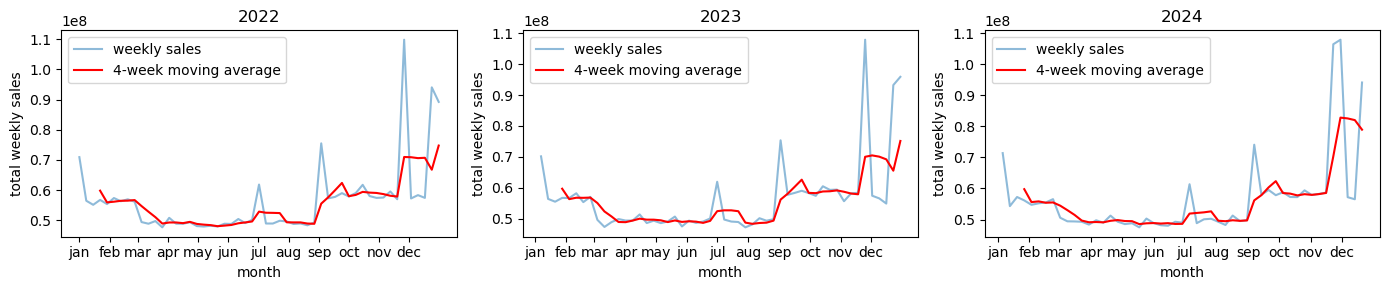

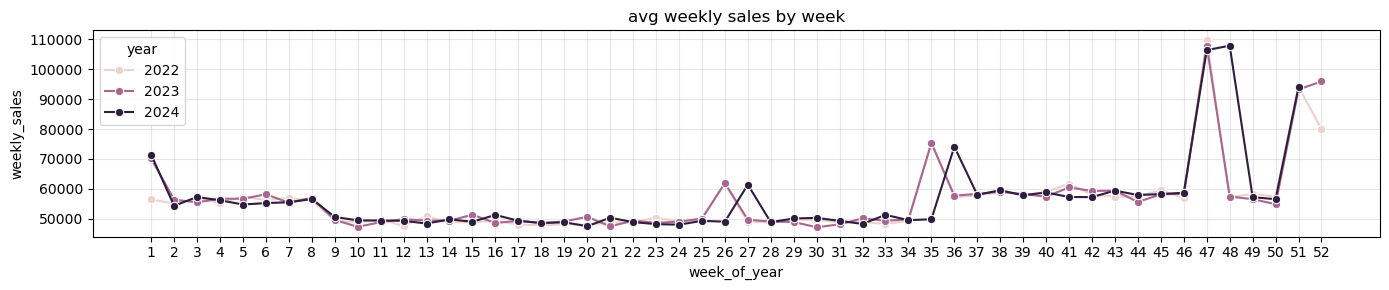

In [16]:
# figure A: weekly sales trends by year
overall_weekly_sales = retail_sales.groupby('date')['weekly_sales'].sum().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, year in zip(axes, sorted(retail_sales['year'].unique())):
    data = overall_weekly_sales[overall_weekly_sales.index.year == year]

    ax.plot(data.index, data.values, alpha=0.5, label='weekly sales')
    ax.plot(data.index, data.rolling(4).mean(), color='red', label='4-week moving average')
    ax.set(title=year, xlabel='month', ylabel='total weekly sales')
    ax.set_xticks(pd.date_range(f'{year}-01-01', f'{year}-12-01', freq='MS'))
    ax.set_xticklabels(['jan', 'feb', 'mar', 'apr', 'may', 'jun',
                        'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])
    ax.legend()

plt.tight_layout()
plt.show()


# figure B: average weekly sales by week of year
weekly_sales = retail_sales.groupby(['year', 'week_of_year'])['weekly_sales'].mean().reset_index()

plt.figure(figsize=(14, 3))
sns.lineplot(data=weekly_sales, x='week_of_year', y='weekly_sales', hue='year', marker='o')
plt.title('avg weekly sales by week')
plt.xticks(range(1, 53))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Figure C.1


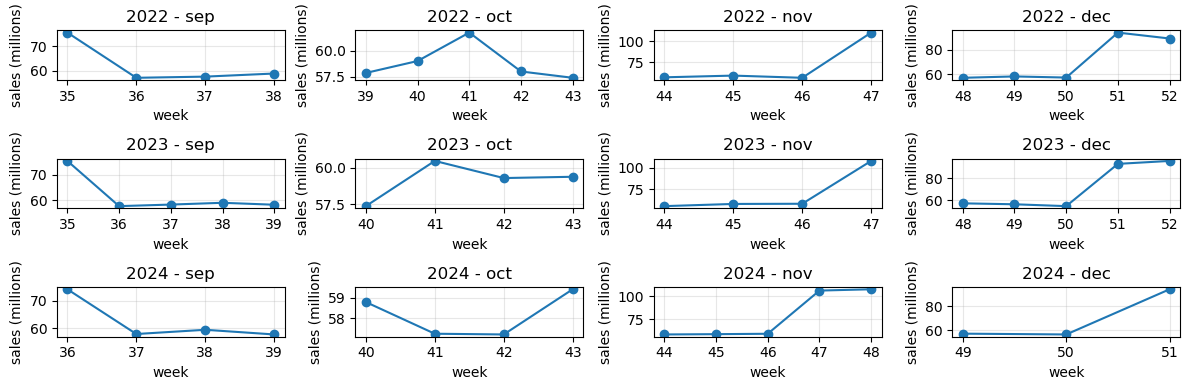

Figure C.2


year,2022,2023,2024
week_of_year,,,
1,unchanged,unchanged,unchanged
2,decrease,decrease,decrease
9,decrease,decrease,decrease
10,decrease,decrease,decrease
18,decrease,decrease,decrease
19,increase,increase,increase
25,increase,increase,increase
28,decrease,decrease,decrease
35,increase,increase,increase


Total weeks where all 3 years match: 16 out of 52


In [17]:
#figure C: subset Q4 for the 3 years to observe and compare the directional differences weekly sales
fig, axes = plt.subplots(3, 4, figsize=(12, 4))

for i, year in enumerate([2022, 2023, 2024]):
    for j, month in enumerate([9, 10, 11, 12]):
        ax = axes[i, j]

        data = retail_sales[
            (retail_sales['year'] == year) &
            (retail_sales['month'] == month)
        ].groupby('week_of_year')['weekly_sales'].sum() / 1_000_000

        ax.plot(data.index, data.values, marker='o')
        ax.set_xticks(data.index)
        ax.set_title(f'{year} - {pd.Timestamp(2024, month, 1).strftime("%b").lower()}')
        ax.set_xlabel('week')
        ax.set_ylabel('sales (millions)')
        ax.grid(alpha=0.3)

print("Figure C.1")
plt.tight_layout()
plt.show()

weekly_sales = retail_sales.groupby(
    ['year', 'week_of_year']
)['weekly_sales'].sum().reset_index()

weekly_sales['direction'] = weekly_sales.groupby('year')['weekly_sales'].diff().apply(
    lambda x: 'increase' if x > 0 else ('decrease' if x < 0 else 'unchanged')
)

direction_table = weekly_sales.pivot(
    index='week_of_year',
    columns='year',
    values='direction'
)

# figure C.2 3 year match
matching_weeks = direction_table[
    direction_table.nunique(axis=1) == 1
].dropna()

print("Figure C.2")
display(matching_weeks)

print(f"Total weeks where all 3 years match: {len(matching_weeks)} out of 52")

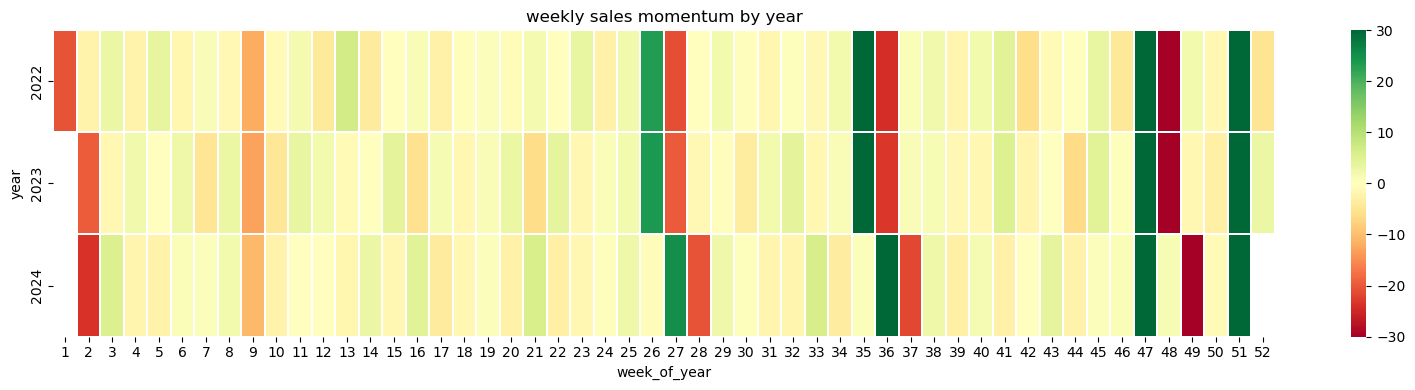


2024 vs 2023
Different direction: 50.0% (25/50 weeks)
Average magnitude difference: 9.65 percentage points

2024 vs 2022
Different direction: 42.0% (21/50 weeks)
Average magnitude difference: 9.68 percentage points

2023 vs 2022
Different direction: 49.0% (25/51 weeks)
Average magnitude difference: 3.55 percentage points


In [ ]:
# aggregate total weekly sales
weekly_data = (
    retail_sales.groupby('date')
    .agg({
        'weekly_sales': 'sum',
        'is_holiday': 'max',
        'week_of_year': 'first'
    })
    .sort_index()
)

# year and WoW change
weekly_data['year'] = weekly_data.index.year

weekly_data['wow_change_pct'] = (
    weekly_data.groupby('year')['weekly_sales']
    .pct_change() * 100
)

# create heatmap
heatmap_data = weekly_data.pivot_table(
    index='year',
    columns='week_of_year',
    values='wow_change_pct',
    aggfunc='mean'
)

plt.figure(figsize=(16, 4))

sns.heatmap(
    heatmap_data.loc[[2022, 2023, 2024]],
    cmap='RdYlGn',
    center=0,
    vmin=-30,
    vmax=30,
    linewidths=0.3,
    cbar_kws={'label': 'wow change (%)'}
)

plt.title('weekly sales momentum by year')
plt.tight_layout()
plt.show()

# compare direction of sales movements
direction = np.sign(heatmap_data)

# compare direction and magnitude of sales movements
for year1, year2 in [(2024, 2023), (2024, 2022), (2023, 2022)]:

    comparison = heatmap_data.loc[[year1, year2]].dropna(axis=1)

    # direction difference
    different = (
        np.sign(comparison.loc[year1]) !=
        np.sign(comparison.loc[year2])
    )

    # magnitude difference in percentage points
    magnitude_diff = (
        comparison.loc[year1] - comparison.loc[year2]
    ).abs()

    print(f'\n{year1} vs {year2}')
    print(f'Different direction: {different.mean() * 100:.1f}% ({different.sum()}/{len(different)} weeks)')
    print(f'Average magnitude difference: {magnitude_diff.mean():.2f} percentage points')

Figure D


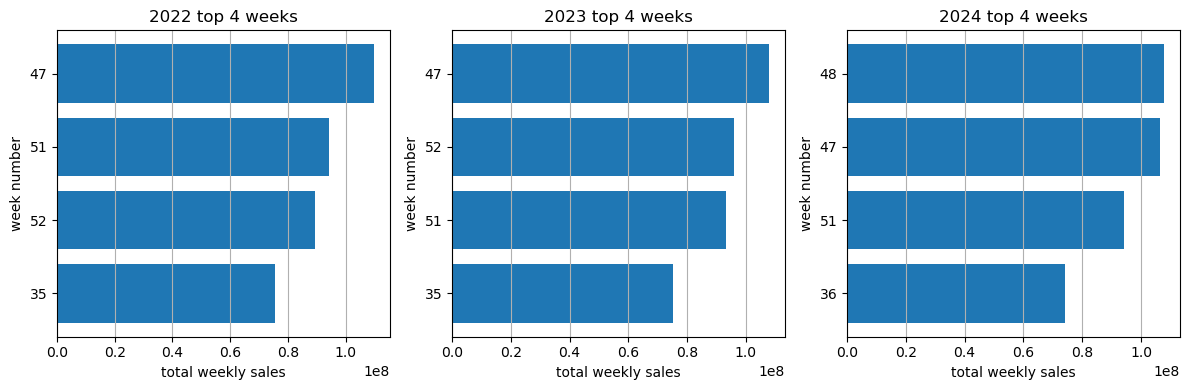

In [ ]:
# figure D: top 4 weeks by year
top_weeks = (
    retail_sales.groupby(['year', 'week_of_year', 'date'])['weekly_sales']
    .sum()
    .reset_index()
    .sort_values('weekly_sales', ascending=False)
    .groupby('year')
    .head(4)
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, year in zip(axes, sorted(top_weeks['year'].unique())):
    data = top_weeks[top_weeks['year'] == year].sort_values('weekly_sales')

    ax.barh(data['week_of_year'].astype(str), data['weekly_sales'])

    ax.set_title(f'{year} top 4 weeks')
    ax.set_xlabel('total weekly sales')
    ax.set_ylabel('week number')
    ax.grid(axis='x')

print("Figure D")
plt.tight_layout()
plt.show()

### How much do holidays affect weekly sales? Are they consistent across all years? And does each holiday product different sales magnitudes?

Data Findings:
- *Weekly sales across different holiday types differ and across years the sales are relatively the same in volume for each type*
- *Although each year follows the same holiday schedule and includes six holidays, their sales coverage differs: Black Friday spans two weeks in 2024, while Christmas spans two weeks in 2022 and 2023 but only one week in 2024. Which help explain the sales pattern differences*

Predictive Signals:
- *holiday and specific holiday_name - to predict annual holiday spikes*

In [41]:
print("number of holidays per year:", retail_sales[retail_sales['is_holiday'] == 1].groupby('year')['date'].nunique())

display(
    retail_sales[retail_sales['is_holiday'] == 1]
    .groupby(['year', 'month', 'week_of_year', 'date', 'holiday_name'])
    ['weekly_sales']
    .sum()
    .div(1000000)
    .reset_index()
    .sort_values(['year', 'date'])
)

number of holidays per year: year
2022    6
2023    6
2024    6
Name: date, dtype: int64


,year,month,week_of_year,date,holiday_name,weekly_sales
0,2022,1,52,2022-01-01,New Year,70.902987
1,2022,7,26,2022-07-02,Independence Day,61.815669
2,2022,9,35,2022-09-03,Labor Day,75.474553
3,2022,11,47,2022-11-26,Black Friday,109.851798
4,2022,12,51,2022-12-24,Christmas,94.049880
5,2022,12,52,2022-12-31,Christmas,89.226725
6,2023,1,1,2023-01-07,New Year,70.142838
7,2023,7,26,2023-07-01,Independence Day,61.919395
8,2023,9,35,2023-09-02,Labor Day,75.339416
9,2023,11,47,2023-11-25,Black Friday,107.901544


number of holidays per year: year
2022    6
2023    6
2024    6
Name: date, dtype: int64


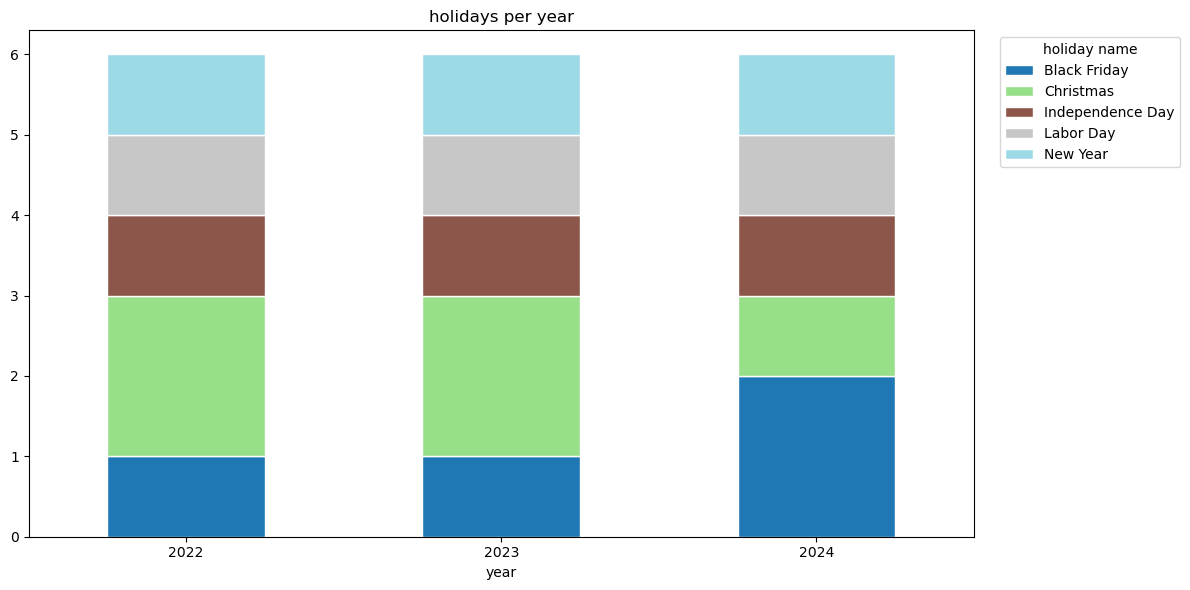

,year,month,week_of_year,date,holiday_name,weekly_sales
0,2022,1,52,2022-01-01,New Year,70.902987
1,2022,7,26,2022-07-02,Independence Day,61.815669
2,2022,9,35,2022-09-03,Labor Day,75.474553
3,2022,11,47,2022-11-26,Black Friday,109.851798
4,2022,12,51,2022-12-24,Christmas,94.049880
5,2022,12,52,2022-12-31,Christmas,89.226725
6,2023,1,1,2023-01-07,New Year,70.142838
7,2023,7,26,2023-07-01,Independence Day,61.919395
8,2023,9,35,2023-09-02,Labor Day,75.339416
9,2023,11,47,2023-11-25,Black Friday,107.901544


In [39]:
# display holiday weeks
print("number of holidays per year:", retail_sales[retail_sales['is_holiday'] == 1].groupby('year')['date'].nunique())

# stacked bar count of holidays per year
holiday_counts = (
    retail_sales[retail_sales['is_holiday'] == 1]
    .groupby(['year', 'holiday_name'])['date']
    .nunique()
    .unstack(fill_value=0)
)

holiday_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab20',
    edgecolor='white'
)

plt.title('holidays per year')
plt.xticks(rotation=0)
plt.legend(title='holiday name', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# table holidays across time
display(
    retail_sales[retail_sales['is_holiday'] == 1]
    .groupby(['year', 'month', 'week_of_year', 'date', 'holiday_name'])['weekly_sales']
    .sum()
    .div(1000000)
    .reset_index()
    .sort_values(['year', 'date'])
)


holiday vs. non-holiday % diff avg. weekly sales:
year
2022    57.74
2023    58.81
2024    63.09
dtype: float64


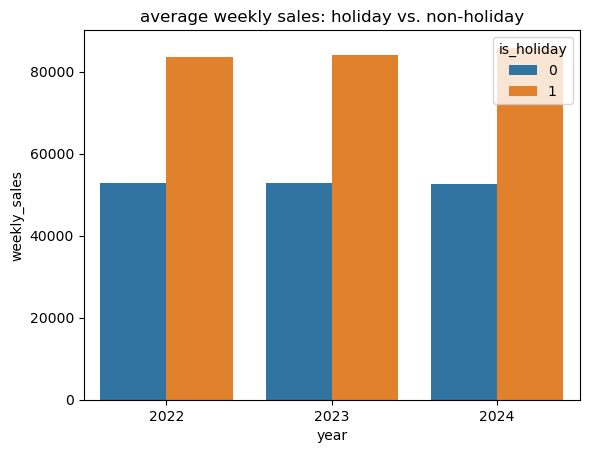

In [44]:
sales = retail_sales.groupby(['year', 'is_holiday'])['weekly_sales'].mean().unstack()

print("holiday vs. non-holiday % diff avg. weekly sales:")
print(((sales[1] / sales[0] - 1) * 100).round(2))

sns.barplot(data=retail_sales, x='year', y='weekly_sales', hue='is_holiday', errorbar=None)
plt.title('average weekly sales: holiday vs. non-holiday')
plt.show()

Caveat: The 2024 Black Friday sale spans two weeks, while the Christmas sale spans two weeks in 2022 and 2023 but only one week in 2024.


Text(0.5, 1.0, 'total holiday sales')

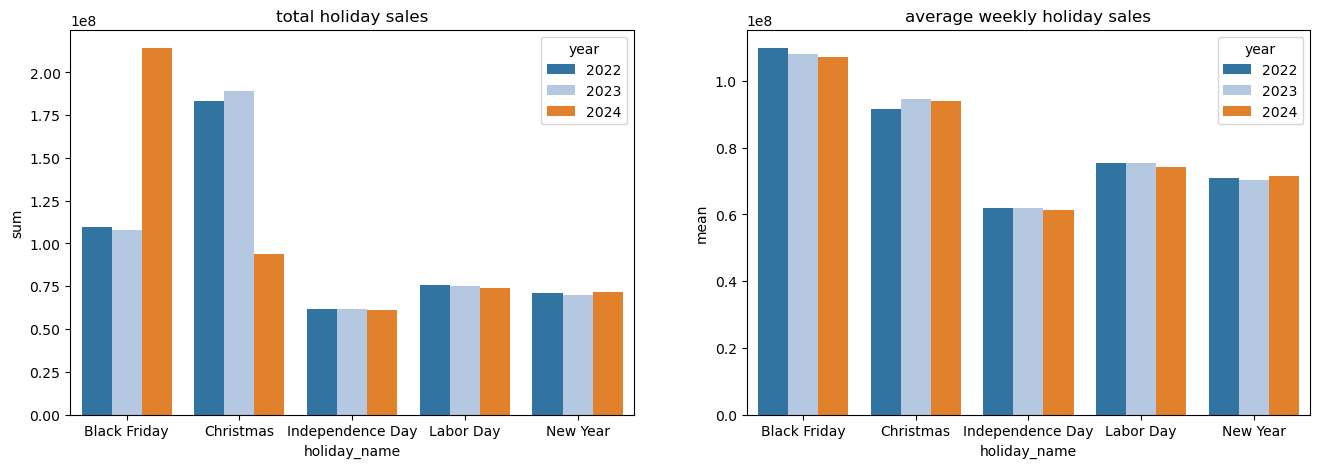

In [37]:
holiday_sales = retail_sales[retail_sales['is_holiday'] == 1].groupby(
    ['year', 'holiday_name', 'date']
)['weekly_sales'].sum().reset_index()

holiday_summary = holiday_sales.groupby(
    ['year', 'holiday_name']
)['weekly_sales'].agg(['sum', 'mean']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# average weekly sales
print("Caveat: The 2024 Black Friday sale spans two weeks, while the Christmas sale spans two weeks in 2022 and 2023 but only one week in 2024.")
sns.barplot(data=holiday_summary, x='holiday_name', y='mean', hue='year', ax=axes[1], palette='tab20')
axes[1].set_title('average weekly holiday sales')

# total sales
sns.barplot(data=holiday_summary, x='holiday_name', y='sum', hue='year', ax=axes[0], palette='tab20')
axes[0].set_title('total holiday sales')

### Do macro-economic factors like cpi, unemployment and promotional markdowns and its changes have a correlation with the movement of weekly sales?

Data Findings:
- *Very weak correlation among these factors movements with weekly sales movements; unemployment (-0.012), CPI (-0.003), and markdowns (-0.021)*

Predictive Signals:
- *None*

pearson correlation matrix


,weekly_sales_change,unemployment_change,cpi_change,markdown_total_change,temperature_change
weekly_sales_change,1.000000,-0.011828,-0.002721,-0.020906,-0.072320
unemployment_change,-0.011828,1.000000,-0.027071,-0.056980,0.076043
cpi_change,-0.002721,-0.027071,1.000000,-0.059063,-0.205243
markdown_total_change,-0.020906,-0.056980,-0.059063,1.000000,-0.207840
temperature_change,-0.072320,0.076043,-0.205243,-0.207840,1.000000


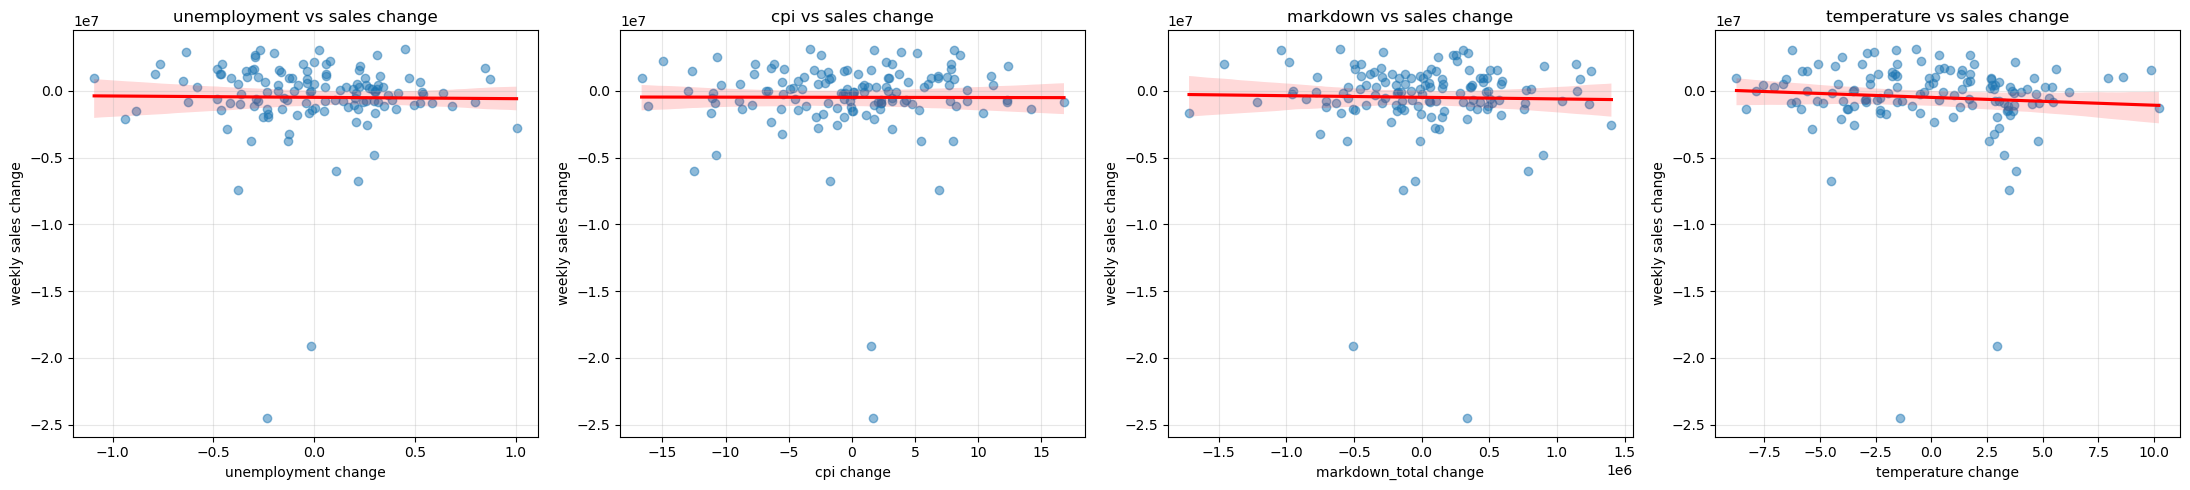

In [80]:
retail_sales['markdown_total'] = retail_sales[
    ['markdown_1', 'markdown_2', 'markdown_3', 'markdown_4', 'markdown_5']
].sum(axis=1)

# aggregate weekly data
weekly_data = retail_sales.groupby('date').agg({
    'weekly_sales': 'sum',
    'unemployment': 'mean',
    'cpi': 'mean',
    'markdown_total': 'sum',
    'temperature': 'mean'
}).sort_index()

# calculate weekly changes
cols = ['weekly_sales', 'unemployment', 'cpi', 'markdown_total', 'temperature']

for col in cols:
    weekly_data[f'{col}_change'] = weekly_data[col].diff()

# remove markdown outliers using iqr
q1 = weekly_data['markdown_total_change'].quantile(0.25)
q3 = weekly_data['markdown_total_change'].quantile(0.75)
iqr = q3 - q1

weekly_filtered = weekly_data[
    weekly_data['markdown_total_change'].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
]

# correlation matrix
features = [
     'weekly_sales_change', 'unemployment_change', 'cpi_change',
     'markdown_total_change', 'temperature_change'
]

print("pearson correlation matrix")
display(weekly_filtered[features].corr())

# plot relationships
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

features = [
    'unemployment_change', 'cpi_change',
    'markdown_total_change', 'temperature_change'
]

titles = [
    'unemployment vs sales change',
    'cpi vs sales change',
    'markdown vs sales change',
    'temperature vs sales change'
]

for ax, feature, title in zip(axes, features, titles):
    sns.regplot(
        data=weekly_filtered,
        x=feature,
        y='weekly_sales_change',
        ax=ax,
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )
    ax.set_title(title)
    ax.set_xlabel(feature.replace('_change', ' change'))
    ax.set_ylabel('weekly sales change')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Feature Engineering

In [ ]:
# aggregate and sort data before splitting
weekly_data = (
    retail_sales.groupby('date')
    .agg({
        'weekly_sales': 'sum',
        'is_holiday': 'max',
        'temperature': 'mean'
    })
    .sort_index()
)

# calculate weekly changes
weekly_data['temp_change_1w'] = weekly_data['temperature'].diff()

weekly_data['sales_change_1w'] = (
    weekly_data['weekly_sales'].shift(1) -
    weekly_data['weekly_sales'].shift(2)
)

# Create date and historical features
weekly_data['year'] = weekly_data.index.year
weekly_data['month'] = weekly_data.index.month
weekly_data['week_of_year'] = weekly_data.index.isocalendar().week.astype(int)
weekly_data['week_sin'] = np.sin(2 * np.pi * weekly_data['week_of_year'] / 52)
weekly_data['week_cos'] = np.cos(2 * np.pi * weekly_data['week_of_year'] / 52)

# Lag features
for lag in [1, 2, 3, 4]:
    weekly_data[f'sales_lag_{lag}'] = weekly_data['weekly_sales'].shift(lag)

# Rolling features
shifted = weekly_data['weekly_sales'].shift(1)
for window in [4]:
    for stat in ['mean', 'std', 'max', 'min']:
        weekly_data[f'rolling_{stat}_{window}'] = (
            getattr(shifted.rolling(window), stat)()
        )

# Interaction features
weekly_data['sales_change_1'] = (
    weekly_data['weekly_sales'].shift(1) -
    weekly_data['weekly_sales'].shift(2)
)

weekly_data['lag1_week_sin'] = weekly_data['sales_lag_1'] * weekly_data['week_sin']
weekly_data['lag1_week_cos'] = weekly_data['sales_lag_1'] * weekly_data['week_cos']
weekly_data['momentum_week_sin'] = weekly_data['sales_change_1'] * weekly_data['week_sin']
weekly_data['momentum_week_cos'] = weekly_data['sales_change_1'] * weekly_data['week_cos']

# Encode features
weekly_data['is_holiday'] = weekly_data['is_holiday'].astype(int)

holiday_dummies = pd.get_dummies(
    retail_sales['holiday_name'], prefix='holiday', dtype=int
)

holiday_dummies.index = retail_sales['date']
holiday_dummies = holiday_dummies.groupby(level=0).max()

# Merge features
weekly_data = weekly_data.join(holiday_dummies)

# Define X and y
feature_cols = [
    'sales_lag_1', 'sales_lag_2', 'sales_lag_3', 'sales_lag_4',
    'rolling_mean_4', 'rolling_std_4', 'rolling_max_4', 
    'is_holiday', 'week_sin', 'week_cos',
    'lag1_week_sin', 'lag1_week_cos',
    'momentum_week_sin', 'momentum_week_cos',
    'temperature'
] + holiday_dummies.columns.tolist()

weekly_data = weekly_data.dropna(subset=feature_cols)

X = weekly_data[feature_cols]
y = weekly_data['weekly_sales']

## Model Train-Test Split Strategy

In [125]:
# Chronological 80/20 split
split_index = int(len(weekly_data) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print('Training:', X_train.shape)
print('Testing:', X_test.shape)
print('Training period:', weekly_data.index[0], 'to', X_train.index[-1])
print('Testing period:', X_test.index[0], 'to', X_test.index[-1])


Training: (121, 20)
Testing: (31, 20)
Training period: 2022-01-29 00:00:00 to 2024-05-18 00:00:00
Testing period: 2024-05-25 00:00:00 to 2024-12-21 00:00:00


## Model Training & Results

### Model A: Linear Regression

model_A MAE: 1043980.6115792247
model_A MAE %: 1.77 %
model_A RMSE: 1307911.8648324446
model_A RMSE %: 2.21 %
model_A WAPE: 1.77 %
model_A R2: 0.9928581196631375


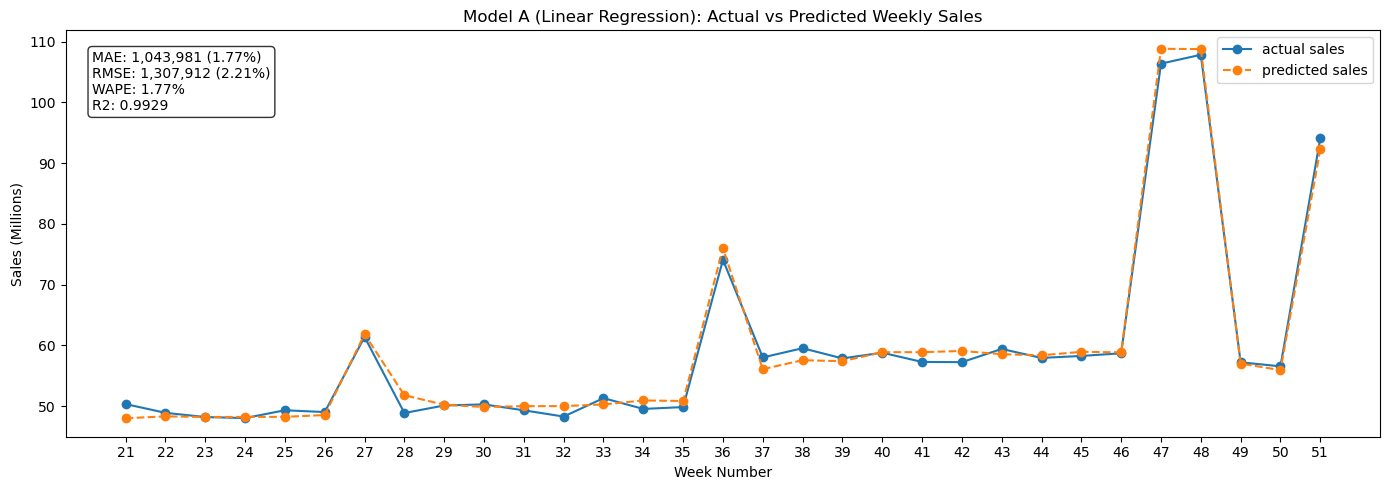

In [142]:
# train model_A
model_A = LinearRegression()
model_A.fit(X_train, y_train)

# predict
y_pred = model_A.predict(X_test)

# combine predictions and actuals
results = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred
}, index=y_test.index)

# calculate metrics
mae = mean_absolute_error(results['actual'], results['predicted'])
rmse = np.sqrt(mean_squared_error(results['actual'], results['predicted']))
r2 = r2_score(results['actual'], results['predicted'])

mae_pct = (mae / results['actual'].mean()) * 100
rmse_pct = (rmse / results['actual'].mean()) * 100
wape = (np.abs(results['actual'] - results['predicted']).sum() /
        np.abs(results['actual']).sum()) * 100

# evaluate weekly sales
print('model_A MAE:', mae)
print('model_A MAE %:', round(mae_pct, 2), '%')
print('model_A RMSE:', rmse)
print('model_A RMSE %:', round(rmse_pct, 2), '%')
print('model_A WAPE:', round(wape, 2), '%')
print('model_A R2:', r2)

# plot actual vs predicted
plt.figure(figsize=(14, 5))

week_numbers = weekly_data.loc[results.index, 'week_of_year']

plt.plot(week_numbers, results['actual'] / 1000000,
         label='actual sales', marker='o')

plt.plot(week_numbers, results['predicted'] / 1000000,
         label='predicted sales', marker='o', linestyle='--')

plt.title('Model A (Linear Regression): Actual vs Predicted Weekly Sales')
plt.xlabel('Week Number')
plt.xticks(
    ticks=week_numbers,
    labels=week_numbers.astype(str)
)

plt.ylabel('Sales (Millions)')
plt.legend()

plt.text(
    0.02, 0.95,
    f"MAE: {mae:,.0f} ({mae_pct:.2f}%)\n"
    f"RMSE: {rmse:,.0f} ({rmse_pct:.2f}%)\n"
    f"WAPE: {wape:.2f}%\n"
    f"R2: {r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.tight_layout()
plt.show()

### Model B: XGBoost (Gradient Boosting)

model_B MAE: 1194228.554193548
model_B MAE %: 2.02122106196513
model_B RMSE: 2442527.6388995815
model_B RMSE %: 4.133956009375133
model_B WAPE: 2.02122106196513
model_B R2: 0.9750922450864258


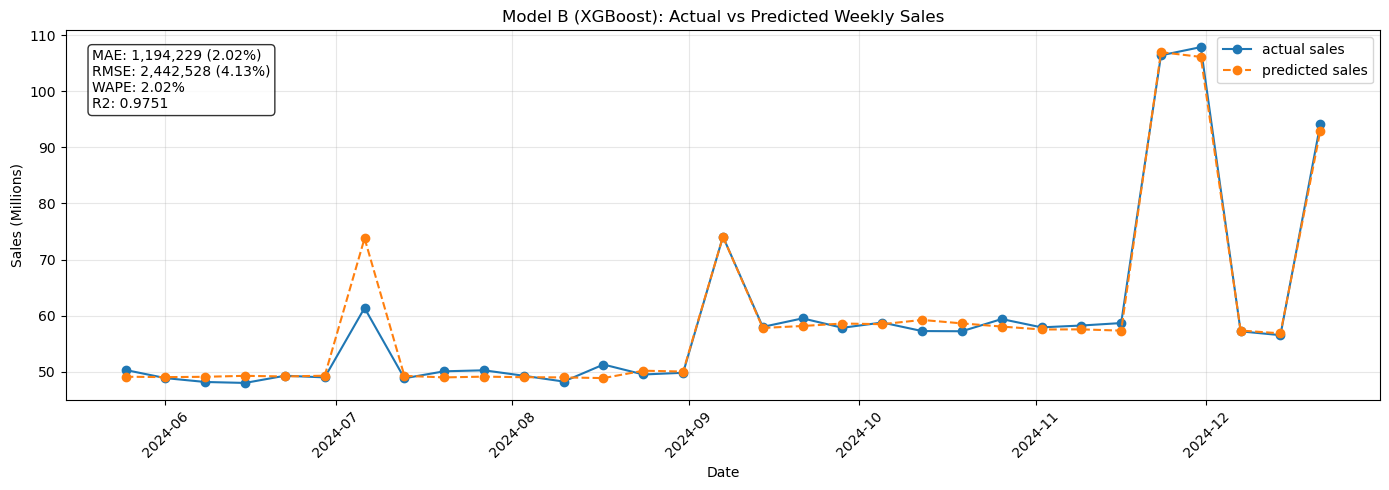

In [136]:
# train model_B
model_B = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    eval_metric='mae',
    random_state=42
)

model_B.fit(X_train, y_train)

# predict
y_pred = model_B.predict(X_test)

# combine predictions and actuals
results = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred
}, index=y_test.index)

# evaluate
mae = mean_absolute_error(results['actual'], results['predicted'])
rmse = np.sqrt(mean_squared_error(results['actual'], results['predicted']))
r2 = r2_score(results['actual'], results['predicted'])

mae_pct = (mae / results['actual'].mean()) * 100
rmse_pct = (rmse / results['actual'].mean()) * 100
wape = (np.abs(results['actual'] - results['predicted']).sum() /
        np.abs(results['actual']).sum()) * 100

print('model_B MAE:', mae)
print('model_B MAE %:', mae_pct)
print('model_B RMSE:', rmse)
print('model_B RMSE %:', rmse_pct)
print('model_B WAPE:', wape)
print('model_B R2:', r2)

# plot actual vs predicted
plt.figure(figsize=(14, 5))

plt.plot(results.index, results['actual'] / 1_000_000,
         label='actual sales', marker='o')

plt.plot(results.index, results['predicted'] / 1_000_000,
         label='predicted sales', marker='o', linestyle='--')

plt.title('Model B (XGBoost): Actual vs Predicted Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Sales (Millions)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.text(
    0.02, 0.95,
    f"MAE: {mae:,.0f} ({mae_pct:.2f}%)\n"
    f"RMSE: {rmse:,.0f} ({rmse_pct:.2f}%)\n"
    f"WAPE: {wape:.2f}%\n"
    f"R2: {r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.tight_layout()
plt.show()

## Champion Model: Linear Regression - Feature Importance

**Feature Ranking:** Seasonality and holiday indicators are the strongest predictors, while interaction features and rolling statistics capture additional sales behavior and fluctuations.

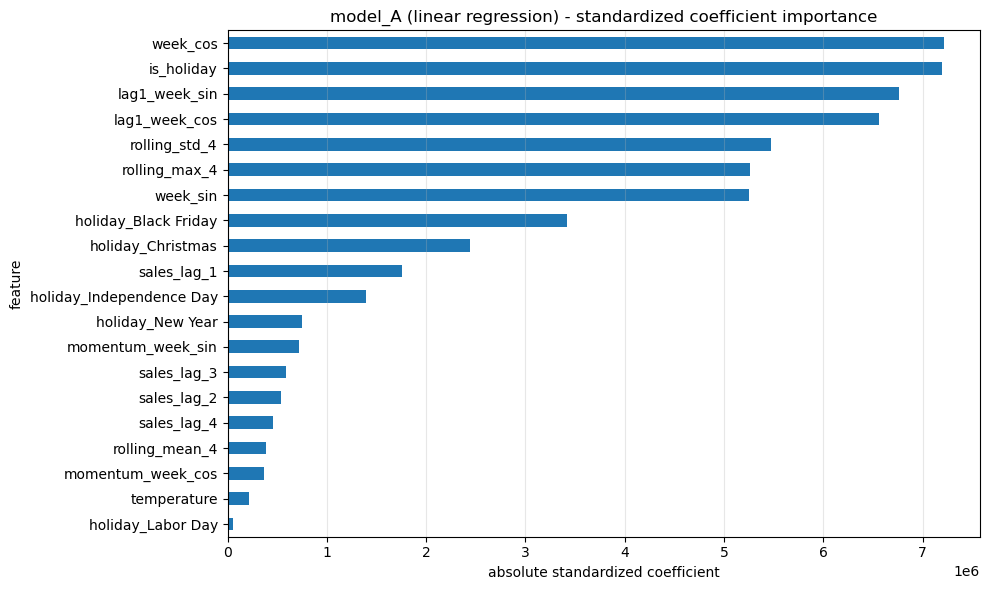

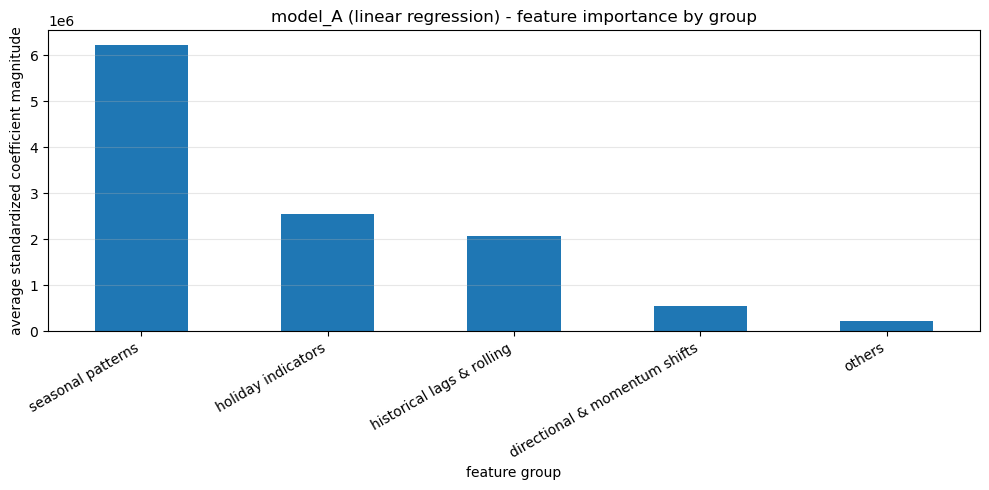

In [137]:

# calculate standardized coefficient magnitudes
importance = pd.Series(
    np.abs(model_A.coef_) * X_train.std().values,
    index=X_train.columns
).sort_values()

plt.figure(figsize=(10, 6))
importance.plot(kind='barh')

plt.title('model_A (linear regression) - standardized coefficient importance')
plt.xlabel('absolute standardized coefficient')
plt.ylabel('feature')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# group features
feature_groups = {
    'historical lags & rolling': ['sales_lag_1', 'sales_lag_2', 'sales_lag_3', 'sales_lag_4', 'rolling_mean_4', 'rolling_std_4', 'rolling_max_4'],
    'seasonal patterns': ['week_sin', 'week_cos'],
    'directional & momentum shifts': ['momentum_week_sin', 'momentum_week_cos'],
    'holiday indicators': ['is_holiday'] + holiday_dummies.columns.tolist(),
    'others': ['temperature']
}

# calculate average importance per group
group_importance = pd.Series({
    group: importance[features].mean()
    for group, features in feature_groups.items()
})

# plot vertical bar chart
plt.figure(figsize=(10, 5))
group_importance.sort_values(ascending=False).plot(kind='bar')

plt.title('model_A (linear regression) - feature importance by group')
plt.xlabel('feature group')
plt.ylabel('average standardized coefficient magnitude')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Champion Model: Linear Regression - Residual Analysis

**Model limitations:** Predictions generally fall within the ±5% error tolerance, but the model struggles with certain week-specific sales movements. This suggests that some short-term fluctuations are not fully captured by the existing features.

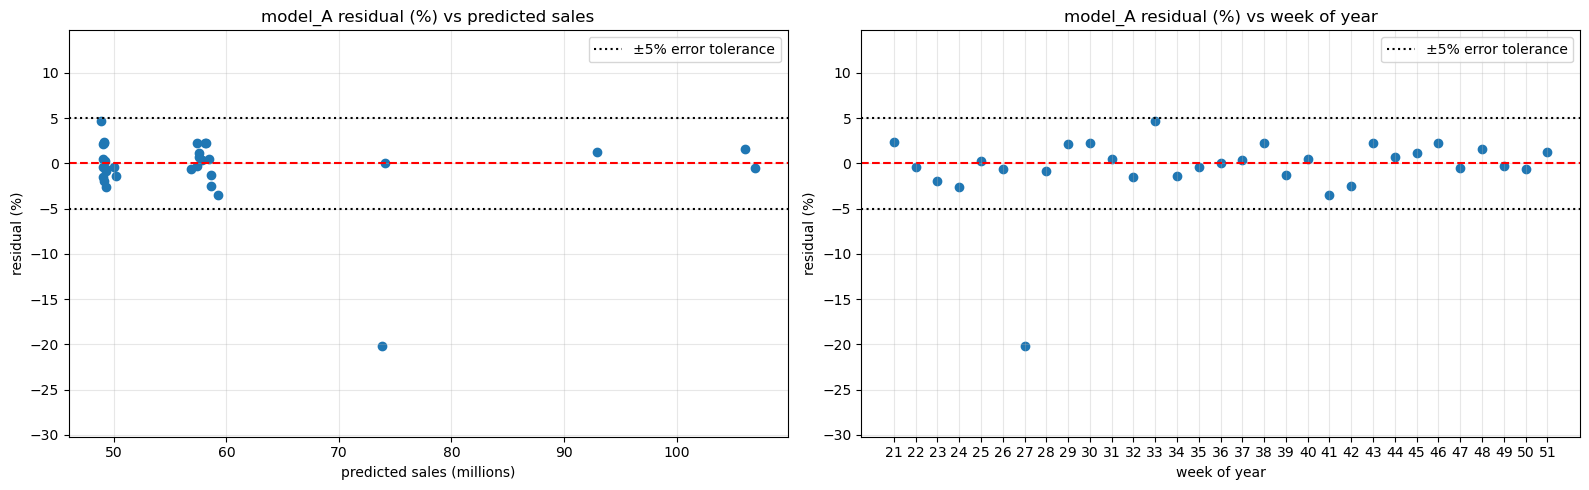

,actual,predicted,residual,residual_pct,flag
date,,,,,
2024-05-25 00:00:00,50.33,49.13,1.20,2.38,
2024-06-01 00:00:00,48.88,49.06,-0.18,-0.36,
2024-06-08 00:00:00,48.19,49.12,-0.93,-1.92,
2024-06-15 00:00:00,48.02,49.29,-1.26,-2.63,
2024-06-22 00:00:00,49.31,49.17,0.13,0.27,
2024-06-29 00:00:00,49.01,49.31,-0.30,-0.62,
2024-07-06 00:00:00,61.38,73.78,-12.40,-20.21,outside ±5%
2024-07-13 00:00:00,48.86,49.29,-0.43,-0.88,
2024-07-20 00:00:00,50.09,49.01,1.09,2.17,


model_A within ±5%: 30
model_A outside ±5%: 1


In [138]:
# calculate residual percentage
results['residual_pct'] = (
    (results['actual'] - results['predicted']) / results['actual']
) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# residual vs predicted sales
axes[0].scatter(results['predicted'] / 1_000_000, results['residual_pct'])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].axhline(5, color='black', linestyle=':', label='±5% error tolerance')
axes[0].axhline(-5, color='black', linestyle=':')
axes[0].set_title('model_A residual (%) vs predicted sales')
axes[0].set_xlabel('predicted sales (millions)')
axes[0].set_ylabel('residual (%)')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_ylim(
    results['residual_pct'].min() - 10,
    results['residual_pct'].max() + 10
)

# residual timeline by actual week number
week_numbers = weekly_data.loc[results.index, 'week_of_year']

axes[1].scatter(week_numbers, results['residual_pct'])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].axhline(5, color='black', linestyle=':', label='±5% error tolerance')
axes[1].axhline(-5, color='black', linestyle=':')
axes[1].set_title('model_A residual (%) vs week of year')
axes[1].set_xlabel('week of year')
axes[1].set_ylabel('residual (%)')
axes[1].set_xticks(sorted(week_numbers.unique()))
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_ylim(
    results['residual_pct'].min() - 10,
    results['residual_pct'].max() + 10
)

plt.tight_layout()
plt.show()

# residual table
residual_analysis = pd.DataFrame({
    'date': y_test.index,
    'actual': y_test / 1e6,
    'predicted': y_pred / 1e6
})

residual_analysis['residual'] = (
    residual_analysis['actual'] - residual_analysis['predicted']
)

residual_analysis['residual_pct'] = (
    residual_analysis['residual'] / residual_analysis['actual']
) * 100

residual_analysis['flag'] = np.where(
    residual_analysis['residual_pct'].abs() > 5,
    'outside ±5%',
    ''
)

display(
    residual_analysis.set_index('date').style
    .format('{:.2f}', subset=['actual', 'predicted', 'residual', 'residual_pct'])
    .set_properties(**{'font-size': '9pt'})
)

print('model_A within ±5%:', (residual_analysis['flag'] == '').sum())
print('model_A outside ±5%:', (residual_analysis['flag'] == 'outside ±5%').sum())

In [146]:
# test model_A
y_pred_A = model_A.predict(X_test)

# calculate residual percentage using test predictions
residual_pct_A = (
    (y_test - y_pred_A) / y_test
) * 100

# model_A WAPE on test set
wape_A = (
    np.sum(np.abs(y_test - y_pred_A)) /
    np.sum(np.abs(y_test))
) * 100

# model_A percentage of test predictions within ±5%
within_5_A = (residual_pct_A.abs() <= 5).mean() * 100

# model_A R-squared on test set
r2_A = r2_score(y_test, y_pred_A)

# print test results

print(f'WAPE: {wape_A:.2f}%')
print(f'Within ±5% error tolerance: {within_5_A:.2f}% of weeks')
print(f'R²: {r2_A:.4f}')

WAPE: 1.77%
Within ±5% error tolerance: 96.77% of weeks
R²: 0.9929


## Final Business Interpretation & Insights

### **Key Data Findings**

1. **Seasonality drives recurring sales patterns**  
   Weekly sales generally follow the same annual shape, indicating recurring seasonal patterns.

2. **Recent sales behavior matters more than YoY patterns**  
   Only 16 of 52 weeks had consistent directional movement across all three years, with 2024 showing different spike timing and weekly movements.

3. **Holidays drive sales spikes**  
   Sales magnitude varies by holiday type and event duration, with Black Friday and Christmas having different durations in 2024.

4. **External factors have limited predictive value**  
   CPI, unemployment, and promotional markdowns showed weak correlations with sales compared with historical and calendar-related variables.

### **Why the Features Worked**

1. **Lag features capture short-term sales behavior** (`sales_lag_1`, `sales_lag_2`, `sales_lag_3`, `sales_lag_4`)  
   Historical `weekly_sales` provide signals about recent movements and future demand. Prioritized short-term patterns because weekly sales direction was inconsistent year over year (only 16 of 52 weeks had consistent directional movement).

2. **Rolling statistics capture recent sales patterns** (`rolling_mean_4`, `rolling_std_4`, `rolling_max_4`)  
   Rolling averages, volatility, and maximum values provide context on recent sales levels and spikes, helping distinguish normal sales activity from unusual movements.

3. **Week sin/cos capture cyclical seasonality** (`week_sin`, `week_cos`)  
   Represent recurring annual patterns while accounting for the cyclical relationship between weeks. Preferred over raw `week_of_year` because the cyclical encoding performed better in testing.

4. **Interaction features capture combined effects** (`lag1_week_sin`, `lag1_week_cos`, `momentum_week_sin`)  
   Combine recent sales behavior with seasonal positioning, allowing the model to account for how sales levels and momentum vary throughout the year.

5. **Holiday indicators capture event-driven demand** (`is_holiday`, `holiday_dummies`)  
   Identify holiday-related sales spikes and distinguish differences in sales behavior across holiday types.